In [1]:
import torch
import torch.nn as nn

In [ ]:
image = torch.rand(1,1,28,28)

conv = nn.Conv2d(
    in_channels=1,
    out_channels=8,
    kernel_size=3,
    stride=3,
    padding=3
)

output = conv(image)

print("Input Image: ", image.shape)
print("output image: ", output.shape)

Input Image:  torch.Size([1, 1, 28, 28])
output image:  torch.Size([1, 8, 11, 11])


#### POOLING

In [8]:
x = torch.randn(1,8,28,28)
pool = nn.MaxPool2d(kernel_size=2)

y = pool(x)


print("Before pooling: ", x.shape)
print("After pooling: ", y.shape)

Before pooling:  torch.Size([1, 8, 28, 28])
After pooling:  torch.Size([1, 8, 14, 14])


Using device: cpu
Epoch: 1 | Loss: 0.3055
Epoch: 2 | Loss: 0.0911
Epoch: 3 | Loss: 0.0642
Test Accuracy: 98.15%
Model successfully saved


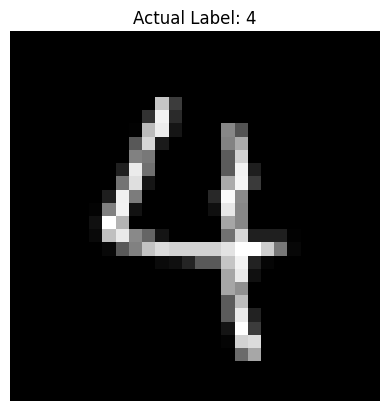

User picked image index: 24
Actual Label: 4
Model Prediction: 4


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.datasets import MNIST
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

transform = transforms.ToTensor()

train_data = MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = MNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),          # 28x28 -> 14x14

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)           # 14x14 -> 7x7
        )

        self.classifier = nn.Sequential(
            nn.Linear(16 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x


model = SimpleCNN().to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 3

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch: {epoch+1} | Loss: {avg_loss:.4f}")

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

torch.save(model.state_dict(), "Simple_CNN_MNIST.pth")
print("Model successfully saved")


index = 24
image, true_label = test_data[index]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual Label: {true_label}")
plt.axis("off")
plt.show()

image_input = image.unsqueeze(0).to(device)   # shape: (1, 1, 28, 28)

model.eval()
with torch.no_grad():
    output = model(image_input)
    predicted_label = output.argmax(dim=1).item()

print("User picked image index:", index)
print("Actual Label:", true_label)
print("Model Prediction:", predicted_label)